# 00 — Tổng quan: Nhận dạng giọng nói y khoa Việt–Anh (Task 2)

> Notebook trình bày, **không huấn luyện lại**. Mọi bảng và hình được tính từ file kết quả đã lưu trong `saved/`, chạy lại an toàn trên CPU. Log huấn luyện đã được rút gọn (bỏ thanh tiến độ, giữ mọi kết quả eval); bản đầy đủ nằm trong `ASR/notebooks/local` và `ASR/local/logs`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
S = next(p / 'saved' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'saved/tables').is_dir())
T = S / 'tables'
def js(rel): return json.loads((S / rel).read_text(encoding='utf-8'))
def show_log(name): print((S / 'logs' / name).read_text(encoding='utf-8'))
def history(name): return js(f'runs/{name}_trainer_state.json')['log_history']
pd.set_option('display.precision', 2)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
C = {'Baseline 1': '#7E9C9B', 'Baseline 2': '#A9C2C0', 'V1': '#0F4E57', 'V2': '#1A6771', 'V-Final': '#FFB21A'}

| Tên trình bày | Mô hình | Thư mục thí nghiệm trong ASR |
|---|---|---|
| Baseline 1 | PhoWhisper-small, chưa huấn luyện | `B0_phowhisper_small_zeroshot` |
| Baseline 2 | Whisper-small, chưa huấn luyện | `B1_whisper_small_zeroshot` |
| V1 | PhoWhisper-small + LoRA, lr 1e-3, trộn 4 nguồn | `V1_phowhisper_small_lora` |
| V2 | V1 train tiếp, lr 1e-4 | `V2_phowhisper_small_lora_cont` |
| V-Final | Whisper-large-v3 + LoRA + SpecAugment + oversampling thuật ngữ hiếm, beam 5 | `O3W_whisper_large_v3_lora_official_termos` |

| Yêu cầu Task 2 | Notebook |
|---|---|
| Thống kê nguồn, làm sạch, mất cân bằng, chia tập | `01_Du_lieu` |
| 2 baseline, so với paper, gap analysis | `02_Baseline` |
| V1: kiến trúc, đường cong loss/WER, tín hiệu cải thiện, phân tích lỗi, cặp từ nhầm | `03_V1` |
| V2: cải tiến từ phân tích lỗi V1 | `04_V2` |
| V-Final: cấu hình, TEST/HARD, so với paper, ví dụ đầu ra | `05_V_Final` |
| Thí nghiệm thành phần, tính khả thi | `06_Thanh_phan_Kha_thi` |

## Kết quả trên cùng DEV chính thức (5.168 clip)

In [2]:
def dev_row(name):
    m = js(f'metrics/{name}.json'); o, s = m['overall'], m['by_source']
    return {'WER %': 100 * o['wer'], 'CER %': 100 * o['cer'], 'Recall thuật ngữ %': 100 * o.get('cs_term_recall', float('nan')),
            **{k: 100 * s[k]['wer'] for k in ['ViMedCSS', 'VietMed', 'FLEURS', 'VIVOS']}}
DEV = pd.DataFrame({'Baseline 1': dev_row('Baseline1_dev'), 'Baseline 2': dev_row('Baseline2_dev'), 'V1': dev_row('V1_dev'),
                    'V2': dev_row('V2_dev'), 'V-Final': dev_row('VFinal_dev_beam5')}).T
DEV

,WER %,CER %,Recall thuật ngữ %,ViMedCSS,VietMed,FLEURS,VIVOS
Baseline 1,24.73,19.25,12.96,28.36,25.87,10.89,0.42
Baseline 2,58.75,46.35,16.05,46.45,73.92,25.61,20.45
V1,18.48,14.36,71.26,16.10,21.80,11.12,6.92
V2,19.08,14.87,72.59,17.29,22.19,11.08,6.16
V-Final,15.07,12.35,81.30,11.38,19.27,6.35,6.23


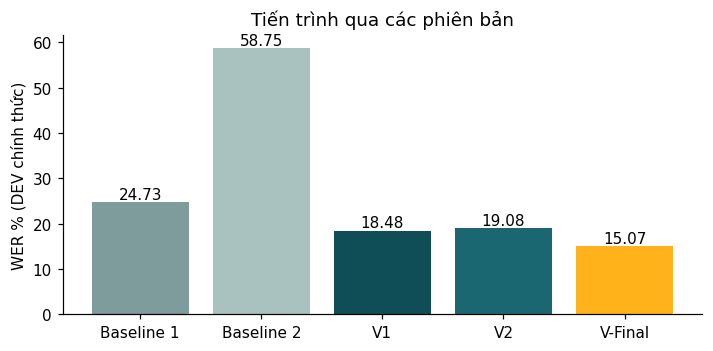

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.3))
bars = ax.bar(DEV.index, DEV['WER %'], color=[C[k] for k in DEV.index])
ax.bar_label(bars, fmt='%.2f'); ax.set_ylabel('WER % (DEV chính thức)'); ax.set_title('Tiến trình qua các phiên bản')
plt.show()

## V-Final trên TEST/HARD chính thức, cùng cách chấm với các mô hình chưa huấn luyện

In [4]:
s = pd.read_csv(T / 'same_metric_official.csv')
lab = {'B0': 'Baseline 1 (PhoWhisper-small)', 'B2': 'PhoWhisper-large', 'B3': 'Whisper-large-v3', 'O3W': 'V-Final'}
s = s[s.system.isin(lab)].assign(system=lambda x: x.system.map(lab))
s.pivot_table(index='system', columns='split', values='wer').reindex(list(lab.values()))

split,HARD,TEST
system,,
Baseline 1 (PhoWhisper-small),36.04,28.02
PhoWhisper-large,27.14,23.14
Whisper-large-v3,33.14,29.61
V-Final,16.42,11.40
